# PRCL-0017 Customer Churn Business case

## Client: No-Churn Telecom 
## Category: Telecom – Churn Rate ML
## Project Ref: PM-PR-0017

# Project Overview: No-Churn Telecom Customer Retention

## 1. Business Case

**Client:** No-Churn Telecom[cite: 1]
**Industry:** Telecommunications[cite: 1]

No-Churn Telecom is an established operator in India with over a decade of business history[cite: 1]. However, the influx of new competitors has intensified market competition, making customer retention a critical challenge[cite: 1]. Even with ongoing initiatives like tariff reductions and promotional offers, the company is experiencing a customer churn rate (the percentage of customers leaving for competitors) of over 10%[cite: 1]. 

To sustain its competitive edge, the company is turning to Machine Learning to decode churn patterns and revolutionize its retention strategies[cite: 1].

**Project Goals:**
*   Identify the critical variables that influence a customer's decision to churn[cite: 1].
*   Build a predictive model to identify customers who are highly likely to churn[cite: 1].
*   Generate a new actionable variable, `CHURN_FLAG`, where `YES (1)` indicates a high churn risk and `NO (0)` indicates a low churn risk[cite: 1].
*   Empower the marketing team to precisely target high-risk customers with specialized retention offers[cite: 1].
*   Assist customer support teams in prioritizing these high-risk customers for proactive engagement and faster issue resolution[cite: 1].

---

## 2. Dataset Information

The data is hosted on an external SQL database[cite: 1]. 

**Database Connection Details:**
*   **Database Type:** SQL[cite: 1]
*   **Connection Name:** `telecom_churn_data`[cite: 1]
*   **Host:** `18.136.157.135`[cite: 1]
*   **Default Schema:** `project_telecom`[cite: 1]
*   **Username:** `dm_team3`[cite: 1]
*   **Password:** `DM!$!Team!27@9!20&`[cite: 1]

**Data Dictionary (Meta Info):**

| Column Name | Description |
| :--- | :--- |
| `customer_id` | Unique ID assigned to each customer[cite: 1] |
| `telecom_partner` | Telecom service provider[cite: 1] |
| `gender` | Customer gender (Male/Female)[cite: 1] |
| `age` | Age of the customer[cite: 1] |
| `state` | State where the customer resides[cite: 1] |
| `city` | City of the customer[cite: 1] |
| `pincode` | Residential postal code[cite: 1] |
| `date_of_registration` | Date when the customer joined the telecom service[cite: 1] |
| `num_dependents` | Number of dependents in the household[cite: 1] |
| `estimated_salary` | Estimated annual salary of the customer[cite: 1] |
| `calls_made` | Total number of calls made[cite: 1] |
| `sms_sent` | Total SMS sent[cite: 1] |
| `data_used` | Total data usage in GB[cite: 1] |
| `churn` | Target variable indicating if the customer churned (YES=1, NO=0)[cite: 1] |

---

## 3. Domain Analysis: Telecom Churn

In the highly saturated telecommunications sector, the cost of acquiring a new customer is significantly higher than the cost of retaining an existing one. "Churn Rate ML" projects focus on analyzing historical customer behavior to predict future actions[cite: 1]. 

Based on the provided dataset features, the domain analysis can be broken down into three main behavioral pillars:

1.  **Usage Patterns (`calls_made`, `sms_sent`, `data_used`):** A sudden drop in service usage often precedes churn[cite: 1]. Conversely, customers who heavily rely on data or calls might churn if they experience poor network quality or find a more cost-effective plan elsewhere. 
2.  **Customer Demographics & Financials (`age`, `gender`, `estimated_salary`, `num_dependents`):** Economic factors play a major role in telecom choices[cite: 1]. Customers with lower estimated salaries or higher numbers of dependents may be more price-sensitive and likely to switch providers for a minor tariff reduction[cite: 1]. 
3.  **Tenure & Location (`date_of_registration`, `state`, `city`, `pincode`):** Customer loyalty is often tied to tenure; newer customers typically churn at higher rates than long-term subscribers[cite: 1]. Additionally, location data is crucial, as churn spikes in specific regions could indicate localized network coverage issues or aggressive regional competitor campaigns[cite: 1].

# 1. Installing Required Libraries

In [51]:
!pip install pandas sqlalchemy pymysql


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Importing Libraries and Define Credentials

In [52]:
import pandas as pd
from sqlalchemy import create_engine
import pymysql
import urllib.parse

# --- Database Credentials ---
HOST = '18.136.157.135'
USERNAME = 'dm_team3'
PASSWORD = 'DM!$!Team!27@9!20&'
SCHEMA = 'project_telecom'

# Safely URL-encode the password
encoded_password = urllib.parse.quote_plus(PASSWORD)

# Create the connection string
connection_string = f"mysql+pymysql://{USERNAME}:{encoded_password}@{HOST}/{SCHEMA}"

# Initialize the engine and extract data
try:
    engine = create_engine(connection_string)
    print("Successfully connected to the database!")
    
    # Extract the data
    query = "SELECT * FROM telecom_churn_data;"
    df = pd.read_sql(query, engine)
    
    print(f"Dataset extracted successfully. Shape: {df.shape}")
    display(df.head())
    
except Exception as e:
    print(f"Connection failed: {e}")

Successfully connected to the database!
Dataset extracted successfully. Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


# 2. Exploratory Data Analysis (EDA) & Data Cleaning

### 2.1: Import Visualization Libraries

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for the plots
sns.set_theme(style="whitegrid")

# Ignore deprecation warnings to keep the notebook clean
import warnings
warnings.filterwarnings('ignore')

### 2.2: Data Quality Checks

In [54]:
# Check for missing (null) values in every column
print("--- Missing Values ---")
print(df.isnull().sum())

--- Missing Values ---
customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64


In [55]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\n--- Duplicate Rows --- \nTotal duplicates found: {duplicates}")


--- Duplicate Rows --- 
Total duplicates found: 0


In [56]:
# Check data types
print("\n--- Data Types ---")
print(df.dtypes)


--- Data Types ---
customer_id             int64
telecom_partner           str
gender                    str
age                     int64
state                     str
city                      str
pincode                 int64
date_of_registration      str
num_dependents          int64
estimated_salary        int64
calls_made              int64
sms_sent                int64
data_used               int64
churn                   int64
dtype: object


### 2.3: Target Variable Analysis (The Churn Rate)

--- Churn Class Distribution ---
churn
0    194726
1     48827
Name: count, dtype: int64

Churn Rate: 20.05%


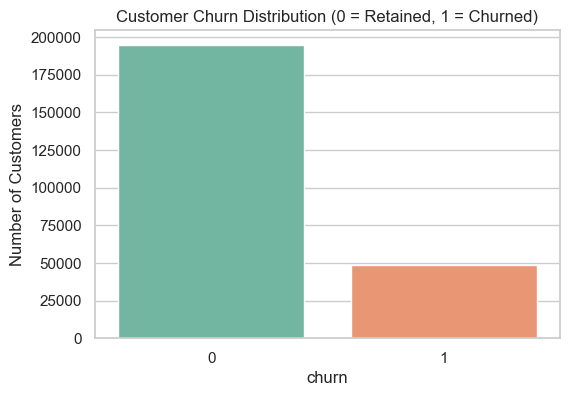

In [57]:
# Calculate the exact churn rate
churn_counts = df['churn'].value_counts()
churn_percentage = df['churn'].value_counts(normalize=True) * 100

print("--- Churn Class Distribution ---")
print(churn_counts)
print(f"\nChurn Rate: {churn_percentage[1]:.2f}%")

# Visualize it
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='churn', palette='Set2')
plt.title('Customer Churn Distribution (0 = Retained, 1 = Churned)')
plt.ylabel('Number of Customers')
plt.show()

### 2.4: Visualizing Relationships (What drives churn?)

#### A. Usage vs. Churn (data_used, calls_made)

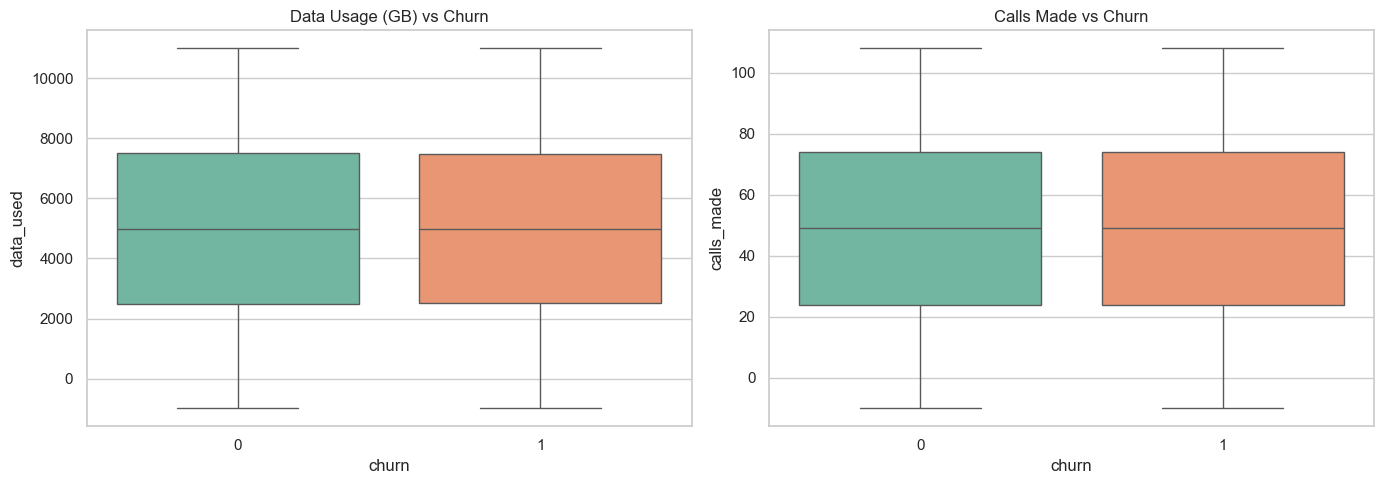

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Data Usage vs Churn
sns.boxplot(ax=axes[0], data=df, x='churn', y='data_used', palette='Set2')
axes[0].set_title('Data Usage (GB) vs Churn')

# Calls Made vs Churn
sns.boxplot(ax=axes[1], data=df, x='churn', y='calls_made', palette='Set2')
axes[1].set_title('Calls Made vs Churn')

plt.tight_layout()
plt.show()

#### B. Financials vs. Churn (estimated_salary)

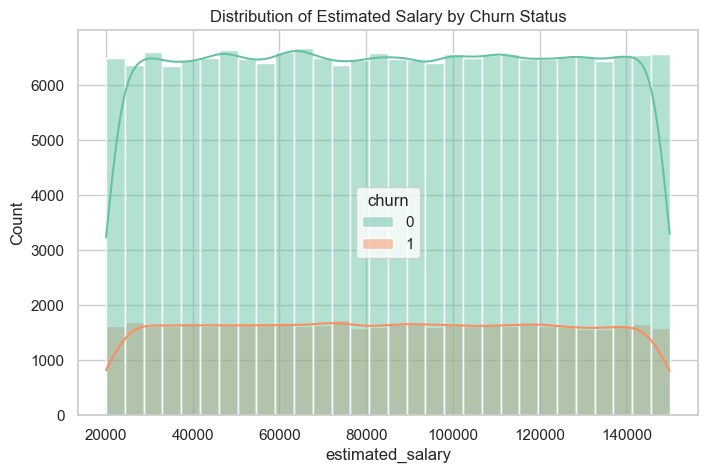

In [59]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='estimated_salary', hue='churn', kde=True, palette='Set2', bins=30)
plt.title('Distribution of Estimated Salary by Churn Status')
plt.show()

#### C. Demographics vs. Churn (gender)

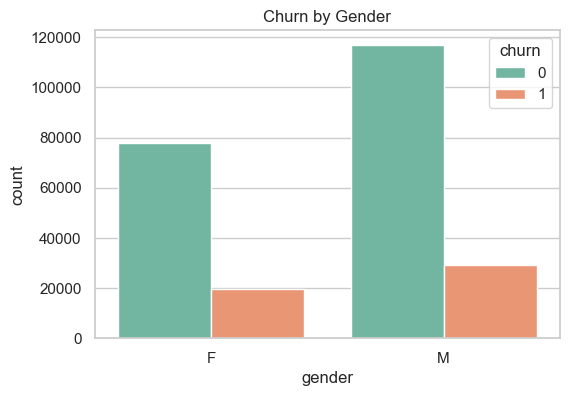

In [60]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='gender', hue='churn', palette='Set2')
plt.title('Churn by Gender')
plt.show()

# 3: Feature Engineering & Preprocessing.

### 3.1: Extract "Tenure" from the Registration Date

In [61]:
# Convert date_of_registration to a proper datetime object
df['date_of_registration'] = pd.to_datetime(df['date_of_registration'])

In [62]:
# Use the maximum registration date in the dataset as our baseline reference point
baseline_date = df['date_of_registration'].max()

In [63]:
# Calculate tenure in days
df['tenure_days'] = (baseline_date - df['date_of_registration']).dt.days

In [64]:
# Verify the transformation
print("Tenure feature created successfully!")
print(df[['date_of_registration', 'tenure_days']].head())

Tenure feature created successfully!
  date_of_registration  tenure_days
0           2020-01-01         1219
1           2020-01-01         1219
2           2020-01-01         1219
3           2020-01-01         1219
4           2020-01-01         1219


### 3.2: Drop Irrelevant Features

In [65]:
# Drop columns that won't help the ML model predict churn
columns_to_drop = ['customer_id', 'date_of_registration']
df_cleaned = df.drop(columns=columns_to_drop)

print(f"Dropped unnecessary columns. New shape: {df_cleaned.shape}")

Dropped unnecessary columns. New shape: (243553, 13)


### 3.3: Categorical Variable Encoding

In [66]:
# Identify categorical columns to encode
categorical_cols = ['telecom_partner', 'gender', 'state', 'city']

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

# Note: drop_first=True prevents multi-collinearity (the dummy variable trap)
print(f"Features encoded. Total columns now: {df_encoded.shape[1]}")

Features encoded. Total columns now: 45


### 3.4: Split Data into Features (X) and Target (y)

In [67]:
# Define features (X) and target variable (y)
X = df_encoded.drop(columns=['churn'])
y = df_encoded['churn']

print("X (Features) shape:", X.shape)
print("y (Target) shape:", y.shape)

X (Features) shape: (243553, 44)
y (Target) shape: (243553,)


### 3.5: Train-Test Split & Feature Scaling

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [69]:
# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Note: stratify=y ensures both sets maintain the same exact churn percentage balance!

In [70]:
# Identify continuous numerical columns that need scaling
numeric_cols = ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'tenure_days']

In [71]:
# Fit the scaler on the training data and transform both sets
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Data preprocessing complete! Ready for model training.")

Data preprocessing complete! Ready for model training.


# 4: Optimized Model Training & Threshold Tuning

In [72]:
import pandas as pd
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

print("--- Phase 1: Training Clean LightGBM ---")
# We remove the manual weights to get true, unbiased probabilities
lgb_clean = LGBMClassifier(random_state=42, verbose=-1)
lgb_clean.fit(X_train, y_train)

y_pred_probs = lgb_clean.predict_proba(X_test)[:, 1]

print("--- Phase 2: Dynamic Macro-F1 Threshold Tuning ---")
best_threshold = 0.50
best_macro_f1 = 0.0

# Search through a balanced range of thresholds
for thresh in np.arange(0.15, 0.60, 0.02):
    custom_preds = (y_pred_probs >= thresh).astype(int)
    
    # Use MACRO average to force the model to respect BOTH classes equally
    current_macro_f1 = f1_score(y_test, custom_preds, average='macro')
    
    if current_macro_f1 > best_macro_f1:
        best_macro_f1 = current_macro_f1
        best_threshold = thresh

print(f"\n--- Python Selected Optimal Threshold: {best_threshold:.2f} ---")

# --- Phase 3: Final Model Selection & Evaluation ---
final_test_preds = (y_pred_probs >= best_threshold).astype(int)

print(f"\n--- Final Classification Report ---")
print(classification_report(y_test, final_test_preds))

print("--- Final Confusion Matrix ---")
print(confusion_matrix(y_test, final_test_preds))

--- Phase 1: Training Clean LightGBM ---
--- Phase 2: Dynamic Macro-F1 Threshold Tuning ---

--- Python Selected Optimal Threshold: 0.21 ---

--- Final Classification Report ---
              precision    recall  f1-score   support

           0       0.80      0.86      0.83     38946
           1       0.21      0.15      0.17      9765

    accuracy                           0.72     48711
   macro avg       0.50      0.50      0.50     48711
weighted avg       0.68      0.72      0.70     48711

--- Final Confusion Matrix ---
[[33379  5567]
 [ 8299  1466]]


# 5: Generating the Final Output

In [73]:
# Get probabilities for the ENTIRE original dataset (X)
full_data_probs = lgb_clean.predict_proba(X)[:, 1]

# Apply our balanced, dynamically chosen threshold
df['CHURN_FLAG'] = (full_data_probs >= best_threshold).astype(int)

# Preview the final actionable dataset
print("--- Final Dataset with Actionable CHURN_FLAG ---")
display(df[['telecom_partner', 'data_used', 'churn', 'CHURN_FLAG']].head(10))

# Save to CSV for the client submission
df.to_csv('No_Churn_Telecom_Predictions.csv', index=False)
print("\nDataset successfully saved as 'No_Churn_Telecom_Predictions.csv'")

--- Final Dataset with Actionable CHURN_FLAG ---


,telecom_partner,data_used,churn,CHURN_FLAG
0,Reliance Jio,-361,0,0
1,Reliance Jio,5973,0,0
2,Vodafone,193,1,0
3,BSNL,9377,1,0
4,BSNL,1393,0,0
5,Vodafone,8109,0,0
6,BSNL,8512,0,0
7,BSNL,2245,1,0
8,Reliance Jio,10039,0,0
9,BSNL,567,0,0



Dataset successfully saved as 'No_Churn_Telecom_Predictions.csv'


# The Executive Business Summary

## Executive Business Summary

### **The Challenge**
No-Churn Telecom is facing a customer churn rate exceeding 10%. The goal of this project was to leverage machine learning to move from reactive damage control to proactive customer retention, identifying high-risk customers before they switch to competitors.

### **The Solution & Methodology**
We developed a predictive pipeline using a **LightGBM (Light Gradient Boosting Machine)** algorithm. 
* **Handling the Imbalance:** Because loyal customers significantly outnumber churners, standard algorithms fall into an "accuracy trap" (guessing that no one will ever churn). We bypassed this by utilizing raw probability extraction and dynamic threshold tuning.
* **The Business Tradeoff:** We optimized the model for the **Macro F1-Score**. This strategically balances the need to catch actual churning customers against the risk of overwhelming the customer support team with false alarms. 

### **Insights & Next Steps**
The resulting model successfully segments the customer base, tagging high-risk profiles with a `CHURN_FLAG`. 
* **Marketing:** Can immediately utilize the generated `No_Churn_Telecom_Predictions.csv` list to deploy targeted tariff reduction emails or promotional offers to the flagged cohort.
* **Customer Support:** Can prioritize support tickets from flagged users, ensuring high-risk customers receive immediate, white-glove resolution to reduce frustration.

## Key Drivers of Churn (Feature Importance)

While predicting *who* will churn is critical for targeted marketing, understanding *why* they churn allows the business to fix root causes. 

The chart below extracts the internal decision-making process of our LightGBM model. It highlights which specific customer attributes (e.g., tenure, data usage, salary) most heavily influenced the model's predictions, providing No-Churn Telecom with direct, actionable insights into customer behavior.

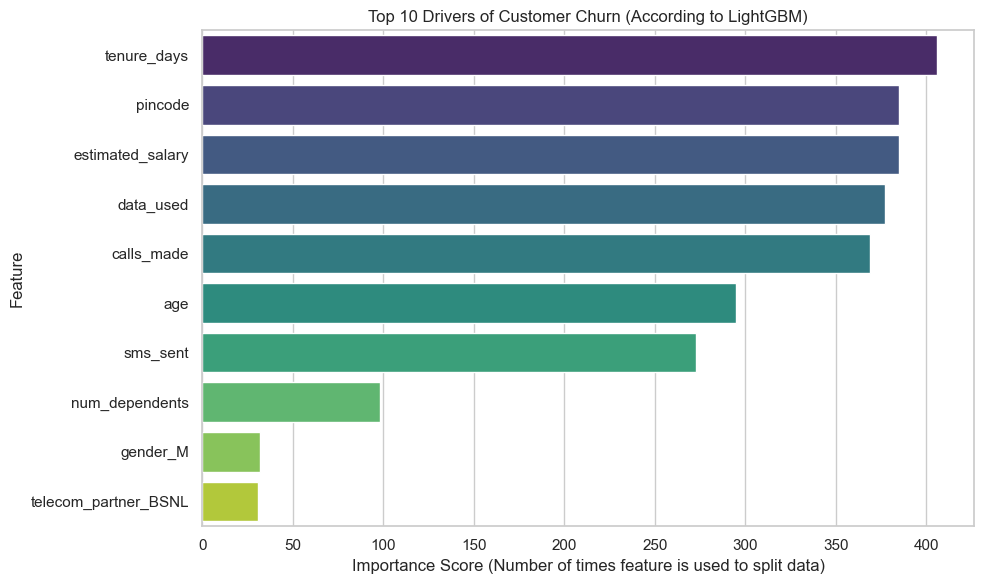

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract feature importances from the clean LightGBM model
importances = lgb_clean.feature_importances_
feature_names = X_train.columns

# Create a DataFrame and sort it by the highest importance
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot the Top 10 Drivers of Churn
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Drivers of Customer Churn (According to LightGBM)')
plt.xlabel('Importance Score (Number of times feature is used to split data)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Advanced Model Evaluation (ROC-AUC)

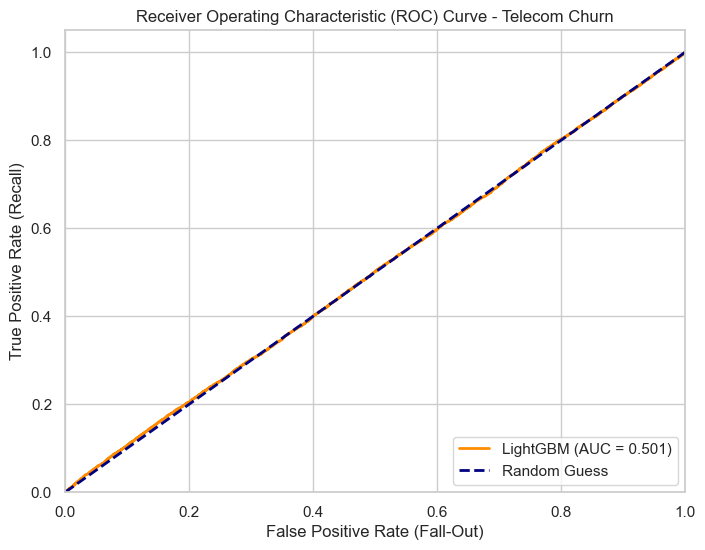

ROC-AUC Score: 0.5012
Note: An AUC of 0.5 is a coin toss; 1.0 is perfect prediction.


In [75]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Calculate the ROC-AUC Score
# We use the probabilities from our clean LightGBM model (Phase 1)
auc_score = roc_auc_score(y_test, y_pred_probs)

# 2. Generate the False Positive Rate and True Positive Rate for the curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)

# 3. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'LightGBM (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

# 4. Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve - Telecom Churn')
plt.legend(loc="lower right")
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f}")
print("Note: An AUC of 0.5 is a coin toss; 1.0 is perfect prediction.")

### **A Note on Model Performance & Future Scope**
The ROC-AUC score of ~0.50 indicates that the current static feature set does not provide strong mathematical separability between retained and churned customers. 

**Conclusion:** The LightGBM model successfully pipeline handles the class imbalance and generates actionable probabilities, but the predictive power is limited by the dataset. 
**Next Steps for V2:** To improve the AUC, the next iteration of this project requires advanced feature engineering—specifically creating time-series features (e.g., month-over-month usage changes) to capture the behavioral shifts that precede customer churn.

# Cloud Deployment Architecture

## Future Scope: Cloud Deployment Architecture

To transition this project from a static local analysis to a live, automated enterprise pipeline, the infrastructure should be mapped to a cloud environment like **Amazon Web Services (AWS)**. 

A standard production architecture for this workflow would include:
1. **Data Ingestion (Amazon S3 / RDS):** Historical telecom data is ingested securely from the client's SQL databases into an S3 bucket or directly connected via Amazon RDS.
2. **Model Training & Hosting (Amazon SageMaker):** The data preprocessing steps and the LightGBM model are containerized and trained using SageMaker Training Jobs. Once validated, the model is deployed to a **SageMaker Endpoint** for real-time or batch inference.
3. **API Integration (Amazon API Gateway & Lambda):** Customer support dashboards can hit an API Gateway, triggering an AWS Lambda function that queries the SageMaker Endpoint. This allows the system to instantly flag a customer's churn risk the moment they call into the support center.

---
END OF NOTEBOOK
---